## Graph 2: Minutes using AI Relative to Time Spent Procrasinating

**Graph Type:** Parallel Coordinate Plot

**Description:** This parallel coordinate plot compares minutes of AI used with time spent procrastinating with each line representing one student and each axis representing a different type of procrastination: sleeping/napping, hanging out with friends, completing easier or other assignments, watching shows/movies, social media (Instagram, TikTok, etc.), and gaming. Lines that rise or fall together across the axes show which kinds of procrastination tend to go along with heavier or lighter AI use. Where lines cluster tightly, a pattern is shared across students. Where they spread out or cross, the relationship is weaker or varies by person.

**Hypothesis:** Students who use AI for more minutes spend less time procrastinating overall, and certain types of procrastination, such as completing easier assignments, are less likely to use as much AI as others, such as gaming or social media.

**Conclusion:** There is no clear relationship between how many minutes students used AI and how they procrastinate. AI usage does not appear to depend on how a student procrastinates, but social media is the dominant procrastination activity across all AI usage levels

**Status:** In Progress

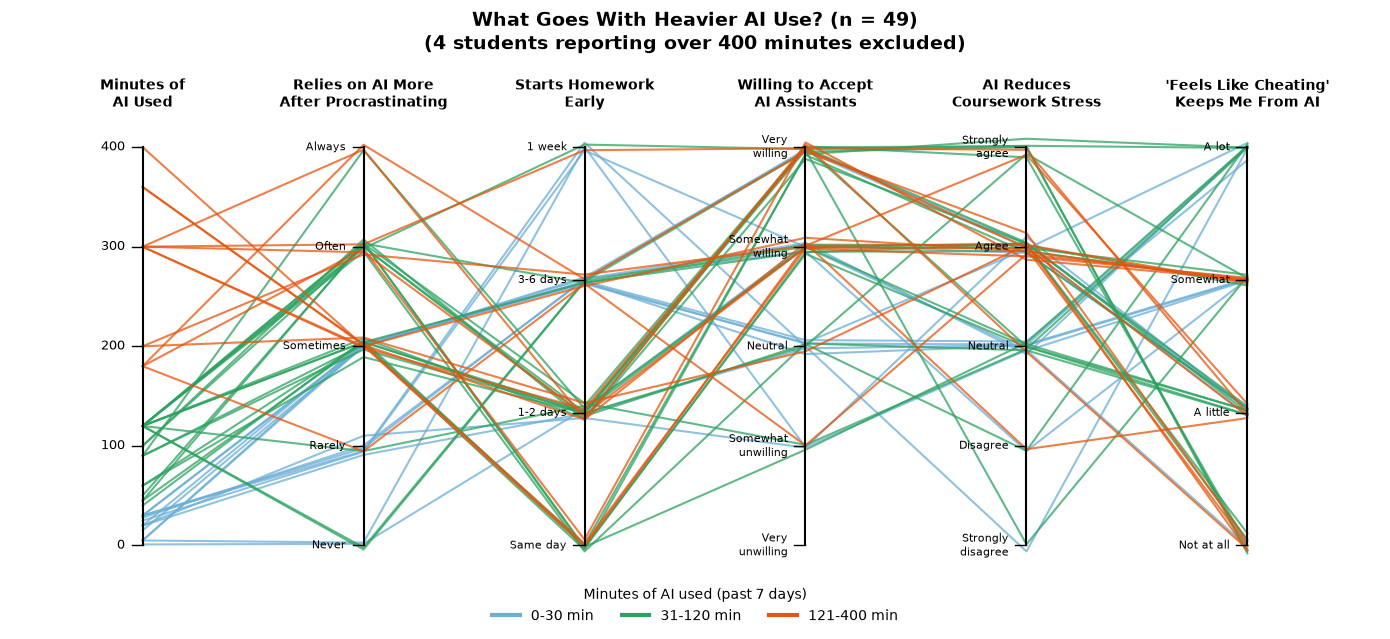

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("survey.csv")


def find_col(*fragments):
    """Return the one column whose name contains every fragment."""
    matches = [c for c in survey_df.columns if all(f in c for f in fragments)]
    assert len(matches) == 1, f"{fragments} matched {len(matches)} columns"
    return matches[0]


freq5 = ["Never", "Rarely", "Sometimes", "Often", "Always"]

axes_spec = [
    ("Relies on AI More\nAfter Procrastinating",
     find_col("I find myself relying on AI more after I procrastinate"),
     freq5),
    ("Starts Homework\nEarly",
     find_col("How far in advance", "[Homework]"),
     ["Same day", "1 - 2 Days Before", "3 - 6 Days Before", "1 Week Before"]),
    ("Willing to Accept\nAI Assistants",
     find_col("How willing are you to accept", "AI Assistants (ChatGPT, Claude)"),
     [1, 2, 3, 4, 5]),
    ("AI Reduces\nCoursework Stress",
     find_col("AI has helped me feel less stressed"),
     ["Strong disagree", "Disagree", "Neutral", "Agree", "Strong agree"]),
    ("'Feels Like Cheating'\nKeeps Me From AI",
     find_col("keep you from using AI", "I feel like I am cheating"),
     ["Not at all", "A little", "Somewhat", "A lot"]),
]

tick_text = {
    "Starts Homework\nEarly": ["Same day", "1-2 days", "3-6 days", "1 week"],
    "Willing to Accept\nAI Assistants": ["Very\nunwilling", "Somewhat\nunwilling", "Neutral",
                                          "Somewhat\nwilling", "Very\nwilling"],
    "AI Reduces\nCoursework Stress": ["Strongly\ndisagree", "Disagree", "Neutral", "Agree",
                                      "Strongly\nagree"],
}

minutes_col = find_col("In the past 7 days, approximately how many minutes")
ai_col = "Minutes of\nAI Used"

df = pd.DataFrame({ai_col: pd.to_numeric(survey_df[minutes_col], errors="coerce")})

axis_names = []
for title, col, labels in axes_spec:
    levels = {lab: i for i, lab in enumerate(labels)}
    raw = survey_df[col]
    if isinstance(labels[0], int):                      # numeric 1-5 questions
        raw = pd.to_numeric(raw, errors="coerce")
    elif raw.dtype == object or str(raw.dtype).startswith("str"):
        raw = raw.astype(str).str.strip()
    df[title] = raw.map(levels) / (len(labels) - 1)
    axis_names.append(title)

df = df.dropna()

ai_cutoff = 400
n_before = len(df)
df = df[df[ai_col] <= ai_cutoff]
n_removed = n_before - len(df)

df = df.sort_values(ai_col)

ai_ticks = [0, 100, 200, 300, 400]
scaled_df = df.copy()
scaled_df[ai_col] = df[ai_col] / ai_cutoff

columns = [ai_col] + axis_names
x = np.arange(len(columns))

bins = [-1, 30, 120, ai_cutoff]
bin_labels = ["0-30 min", "31-120 min", "121-400 min"]
bin_colors = ["#6baed6", "#2ca25f", "#e6550d"]   # light blue, green, orange
group = pd.cut(df[ai_col], bins=bins, labels=bin_labels)
color_map = dict(zip(bin_labels, bin_colors))

# Create the parallel coordinate plot
fig, spg = plt.subplots(figsize=(14, 6.5))
rng = np.random.default_rng(1)
for idx in scaled_df.index:
    y = scaled_df.loc[idx, columns].values.astype(float)
    y[1:] += rng.normal(0, 0.012, len(columns) - 1)    # small jitter so ties don't overlap exactly
    spg.plot(x, y, color=color_map[group[idx]], alpha=0.75, linewidth=1.5)

for xi, col in zip(x, columns):
    spg.plot([xi, xi], [0, 1], color="black", linewidth=1.5)
    spg.text(xi, 1.09, col, ha="center", va="bottom", fontsize=10, fontweight="bold")

for m in ai_ticks:
    pos = m / ai_cutoff
    spg.plot([-0.05, 0], [pos, pos], color="black", linewidth=1)
    spg.text(-0.08, pos, str(m), ha="right", va="center", fontsize=9)

for xi, (title, col, labels) in zip(x[1:], axes_spec):
    names = tick_text.get(title, labels)
    n = len(labels)
    for i, label in enumerate(names):
        pos = i / (n - 1)
        spg.plot([xi - 0.05, xi], [pos, pos], color="black", linewidth=1)
        spg.text(xi - 0.08, pos, label, ha="right", va="center", fontsize=8)

spg.set_xlim(-0.6, len(columns) - 0.4)
spg.set_ylim(-0.05, 1.2)
spg.axis("off")
plt.title(f"What Goes With Heavier AI Use? (n = {len(df)})\n"
f"({n_removed} students reporting over {ai_cutoff} minutes excluded)",
fontsize=14, fontweight="bold", y=1.02)

spg.legend(handles=[Line2D([0], [0], color=c, lw=3, label=l) for l, c in color_map.items()],
title="Minutes of AI used (past 7 days)", loc="upper center",
bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

INSERT ANALYSIS HERE

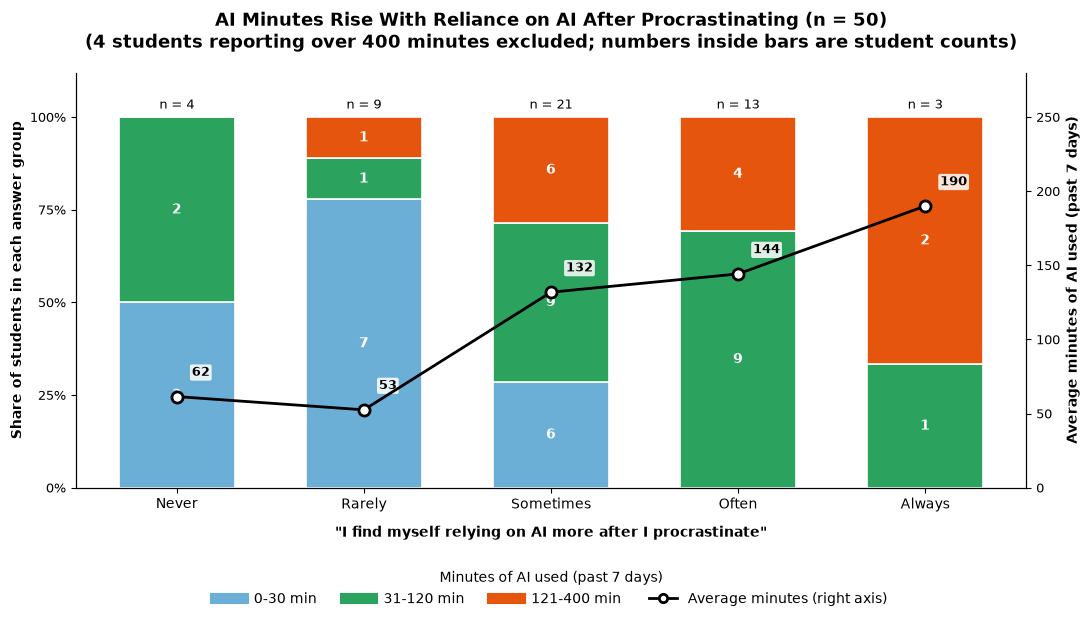

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("survey.csv")


def find_col(*fragments):
    """Return the one column whose name contains every fragment."""
    matches = [c for c in survey_df.columns if all(f in c for f in fragments)]
    assert len(matches) == 1, f"{fragments} matched {len(matches)} columns"
    return matches[0]


# Columns
minutes_col = find_col("In the past 7 days, approximately how many minutes")
reliance_col = find_col("I find myself relying on AI more after I procrastinate")

levels = ["Never", "Rarely", "Sometimes", "Often", "Always"]

df = pd.DataFrame({
    "minutes": pd.to_numeric(survey_df[minutes_col], errors="coerce"),
    "reliance": survey_df[reliance_col].astype(str).str.strip(),
})
df = df[df["reliance"].isin(levels)].dropna()      # drops blanks and double-checked answers


ai_cutoff = 400
n_before = len(df)
df = df[df["minutes"] <= ai_cutoff]
n_removed = n_before - len(df)


bins = [-1, 30, 120, ai_cutoff]
bin_labels = ["0-30 min", "31-120 min", "121-400 min"]
bin_colors = ["#6baed6", "#2ca25f", "#e6550d"]
df["group"] = pd.cut(df["minutes"], bins=bins, labels=bin_labels)


counts = (df.groupby(["reliance", "group"], observed=False).size()
            .unstack("group").reindex(levels).fillna(0))
totals = counts.sum(axis=1)
pct = counts.div(totals, axis=0) * 100
mean_minutes = df.groupby("reliance")["minutes"].mean().reindex(levels)


fig, ax = plt.subplots(figsize=(11, 6.5))
x = np.arange(len(levels))

bottom = np.zeros(len(levels))
for lab, color in zip(bin_labels, bin_colors):
    vals = pct[lab].values
    ax.bar(x, vals, bottom=bottom, color=color, edgecolor="white", linewidth=1.2, width=0.62)
    for xi, v, b, c in zip(x, vals, bottom, counts[lab].values):
        if v >= 8:                                   # only label segments big enough to fit text
            ax.text(xi, b + v / 2, f"{int(c)}", ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    bottom += vals


for xi, n in zip(x, totals.values):
    ax.text(xi, 101.5, f"n = {int(n)}", ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels([f"{t}%" for t in [0, 25, 50, 75, 100]], fontsize=9)
ax.set_ylabel("Share of students in each answer group", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(levels, fontsize=10)
ax.set_xlabel("\"I find myself relying on AI more after I procrastinate\"",
              fontsize=10, fontweight="bold", labelpad=10)


ax2 = ax.twinx()
ax2.plot(x, mean_minutes.values, color="black", marker="o", markersize=8,
         markerfacecolor="white", markeredgewidth=2, linewidth=2, zorder=5)
for xi, m in zip(x, mean_minutes.values):
    ax2.text(xi + 0.08, m + 12, f"{m:.0f}", ha="left", va="bottom", fontsize=9,
             fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax2.set_ylim(0, 280)
ax2.set_ylabel("Average minutes of AI used (past 7 days)", fontsize=10, fontweight="bold")
ax2.tick_params(axis="y", labelsize=9)

for a in (ax, ax2):
    a.spines["top"].set_visible(False)

plt.title(f"AI Minutes Rise With Reliance on AI After Procrastinating (n = {len(df)})\n"
          f"({n_removed} students reporting over {ai_cutoff} minutes excluded; "
          f"numbers inside bars are student counts)",
          fontsize=13, fontweight="bold", y=1.04)

handles = [Line2D([0], [0], color=c, lw=8, label=l) for l, c in zip(bin_labels, bin_colors)]
handles.append(Line2D([0], [0], color="black", marker="o", markerfacecolor="white",
                      markeredgewidth=2, lw=2, label="Average minutes (right axis)"))
ax.legend(handles=handles, title="Minutes of AI used (past 7 days)", loc="upper center",
          bbox_to_anchor=(0.5, -0.17), ncol=4, frameon=False)
plt.tight_layout()
plt.show()